# Neural Networks with Momentum — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/neural-networks-with-momentum.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Neural Networks with Momentum</h1>


<h3>Objectives</h3>    

<ul>
    <li>Train different neural network models using different values for the Momentum parameter</li>
    <li>Compare the results of different Momentum terms</li>


<p>Estimated Time Needed: <strong>25 mins</strong></p>


<h2>Table of Contents</h2>
<p>In this lab, you will see how different values for the momentum parameters affect the convergence rate of a neural network.</p>

<ul>
<li><a href="#Preparation">Preparation</a></li>
<li><a href="#Neural-Network-Module-and-Function-for-Training">Neural Network Module and Function for Training</a></li>
<li><a href="#Train-Different-Neural-Network-Models-using-Different-Values-for-the-Momentum-Parameter">Train Different Neural Network Models using Different Values for the Momentum Parameter</a></li>
<li><a href="#Compare-the-Results-of-Different-Momentum-Terms">Compare the Results of Different Momentum Terms</a></li>
</ul>

<hr>


<h2>Preparation</h2>


We'll need the following libraries:  


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(1)
np.random.seed(1)

Matplotlib is building the font cache; this may take a moment.


Functions used to plot:


In [3]:
def plot_decision_regions_3class(model, data_set):
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#00AAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#00AAFF'])
    X = data_set.x.numpy()
    y = data_set.y.numpy()
    h = 0.02
    x_min, x_max = (X[:, 0].min() - 0.1, X[:, 0].max() + 0.1)
    y_min, y_max = (X[:, 1].min() - 0.1, X[:, 1].max() + 0.1)
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    XX = torch.torch.Tensor(np.c_[xx.ravel(), yy.ravel()])
    _, yhat = torch.max(model(XX), 1)
    yhat = yhat.numpy().reshape(xx.shape)
    plt.pcolormesh(xx, yy, yhat, cmap=cmap_light)
    plt.plot(X[y[:] == 0, 0], X[y[:] == 0, 1], 'ro', label='y=0')
    plt.plot(X[y[:] == 1, 0], X[y[:] == 1, 1], 'go', label='y=1')
    plt.plot(X[y[:] == 2, 0], X[y[:] == 2, 1], 'o', label='y=2')
    plt.title('decision region')
    plt.legend()

Create the dataset class 


In [4]:
class Data(Dataset):

    def __init__(self, K=3, N=500):
        D = 2
        X = np.zeros((N * K, D))
        y = np.zeros(N * K, dtype='uint8')
        for j in range(K):
            ix = range(N * j, N * (j + 1))
            r = np.linspace(0.0, 1, N)
            t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2
            X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
            y[ix] = j
        self.y = torch.from_numpy(y).type(torch.LongTensor)
        self.x = torch.from_numpy(X).type(torch.FloatTensor)
        self.len = y.shape[0]

    def __getitem__(self, index):
        return (self.x[index], self.y[index])

    def __len__(self):
        return self.len

    def plot_data(self):
        plt.plot(self.x[self.y[:] == 0, 0].numpy(), self.x[self.y[:] == 0, 1].numpy(), 'o', label='y=0')
        plt.plot(self.x[self.y[:] == 1, 0].numpy(), self.x[self.y[:] == 1, 1].numpy(), 'ro', label='y=1')
        plt.plot(self.x[self.y[:] == 2, 0].numpy(), self.x[self.y[:] == 2, 1].numpy(), 'go', label='y=2')
        plt.legend()

<!--Empty Space for separating topics-->


<a name="Model"><h2 id="Model">Neural Network Module and Function for Training</h2></a>


Create Neural Network Module using <code>ModuleList()</code>


In [5]:
class Net(nn.Module):

    def __init__(self, Layers):
        super(Net, self).__init__()
        self.hidden = nn.ModuleList()
        for input_size, output_size in zip(Layers, Layers[1:]):
            self.hidden.append(nn.Linear(input_size, output_size))

    def forward(self, activation):
        L = len(self.hidden)
        for l, linear_transform in zip(range(L), self.hidden):
            if l < L - 1:
                activation = F.relu(linear_transform(activation))
            else:
                activation = linear_transform(activation)
        return activation

Create the function for training the model.


In [6]:
def train(data_set, model, criterion, train_loader, optimizer, epochs=2):
    LOSS = []
    ACC = []
    for epoch in itertools.islice(range(epochs), 2):
        for x, y in train_loader:
            optimizer.zero_grad()
            yhat = model(x)
            loss = criterion(yhat, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        LOSS.append(loss.item())
        ACC.append(accuracy(model, data_set))
    results = {'Loss': LOSS, 'Accuracy': ACC}
    fig, ax1 = plt.subplots()
    color = 'tab:red'
    ax1.plot(LOSS, color=color)
    ax1.set_xlabel('epoch', color=color)
    ax1.set_ylabel('total loss', color=color)
    ax1.tick_params(axis='y', color=color)
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('accuracy', color=color)
    ax2.plot(ACC, color=color)
    ax2.tick_params(axis='y', color=color)
    fig.tight_layout()
    plt.show()
    return results

Define a function used to calculate accuracy.


In [7]:
def accuracy(model, data_set):
    _, yhat = torch.max(model(data_set.x), 1)
    return (yhat == data_set.y).numpy().mean()

<!--Empty Space for separating topics-->


<h2>Train Different Neural Network Models using Different Values for the Momentum Parameter</h2>


Crate a dataset object using <code>Data</code>


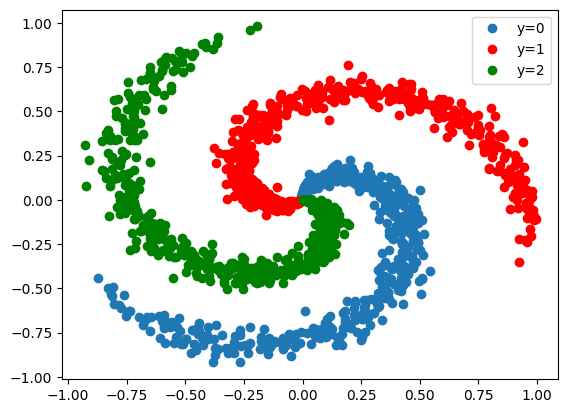

In [8]:
data_set = Data()
data_set.plot_data()
data_set.y = data_set.y.view(-1)

Dictionary to contain different cost and  accuracy values for each epoch  for different values of the momentum parameter.


In [9]:
Results = {'momentum 0': {'Loss': 0, 'Accuracy:': 0}, 'momentum 0.1': {'Loss': 0, 'Accuracy:': 0}}

Create a  network to classify three classes with 1 hidden layer with 50 neurons and a momentum value of zero.


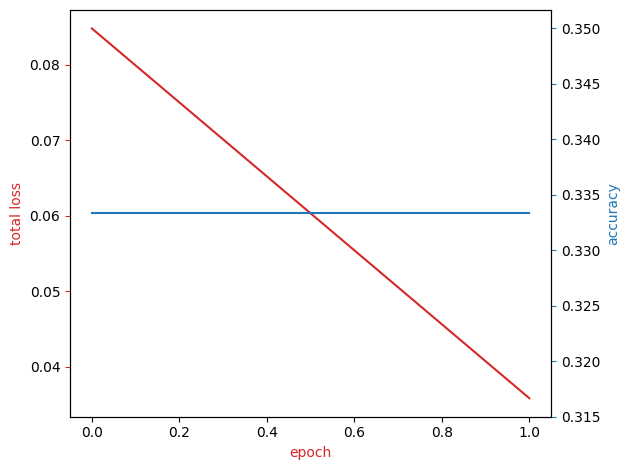

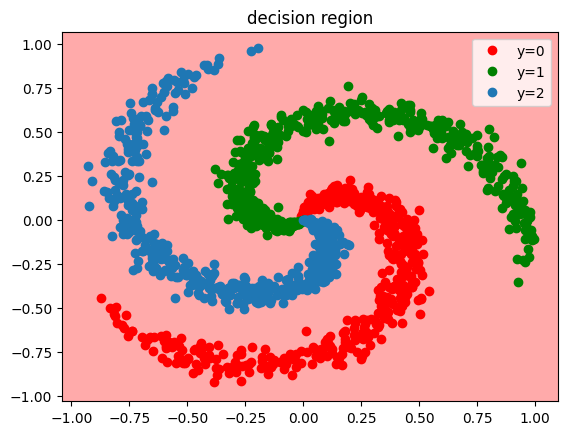

In [10]:
Layers = [2, 50, 3]
model = Net(Layers)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
train_loader = DataLoader(dataset=data_set, batch_size=20)
criterion = nn.CrossEntropyLoss()
Results['momentum 0'] = train(data_set, model, criterion, train_loader, optimizer, epochs=2)
plot_decision_regions_3class(model, data_set)

Create a network to classify three classes with 1 hidden layer with 50 neurons and a momentum value of 0.1.




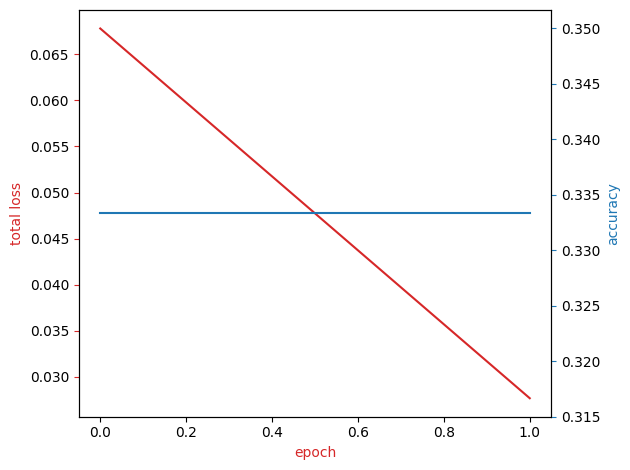

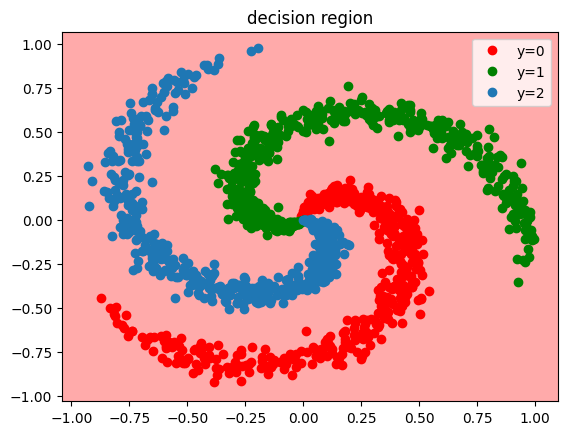

In [11]:
Layers = [2, 50, 3]
model = Net(Layers)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.1)
train_loader = DataLoader(dataset=data_set, batch_size=20)
criterion = nn.CrossEntropyLoss()
Results['momentum 0.1'] = train(data_set, model, criterion, train_loader, optimizer, epochs=2)
plot_decision_regions_3class(model, data_set)


Create a network to classify three classes with 1 hidden layer with 50 neurons and a momentum value of 0.2.


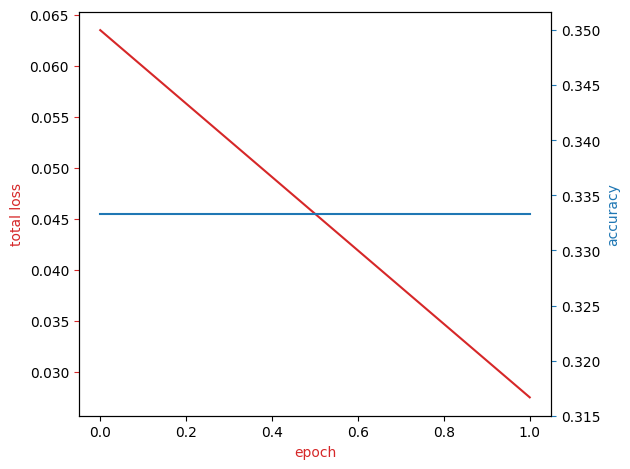

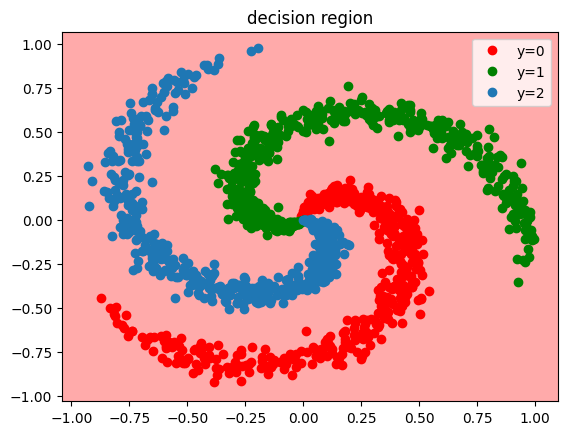

In [12]:
Layers = [2, 50, 3]
model = Net(Layers)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.2)
train_loader = DataLoader(dataset=data_set, batch_size=20)
criterion = nn.CrossEntropyLoss()
Results['momentum 0.2'] = train(data_set, model, criterion, train_loader, optimizer, epochs=2)
plot_decision_regions_3class(model, data_set)

Create a network to classify three classes with 1 hidden layer with 50 neurons and a momentum value of 0.4.


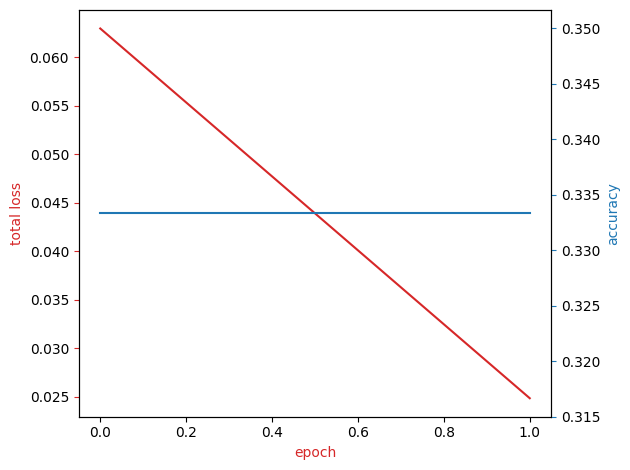

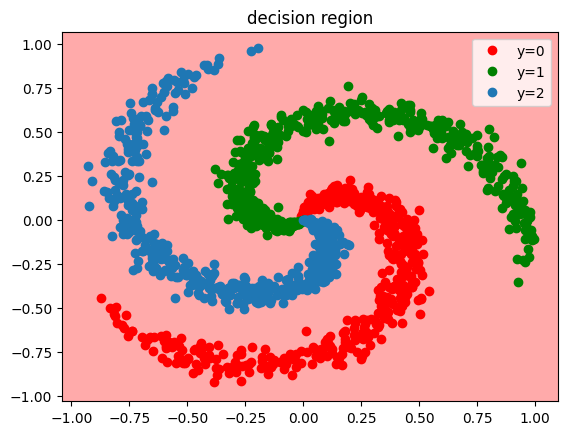

In [13]:
Layers = [2, 50, 3]
model = Net(Layers)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.4)
train_loader = DataLoader(dataset=data_set, batch_size=20)
criterion = nn.CrossEntropyLoss()
Results['momentum 0.4'] = train(data_set, model, criterion, train_loader, optimizer, epochs=2)
plot_decision_regions_3class(model, data_set)

Create a network to classify three classes with 1 hidden layer with 50 neurons and a momentum value of 0.5.


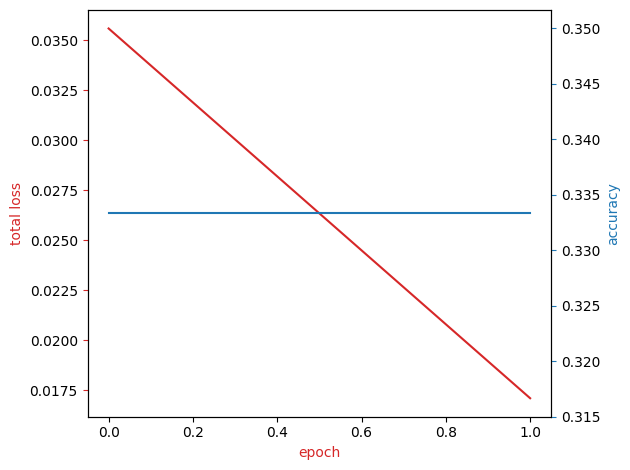

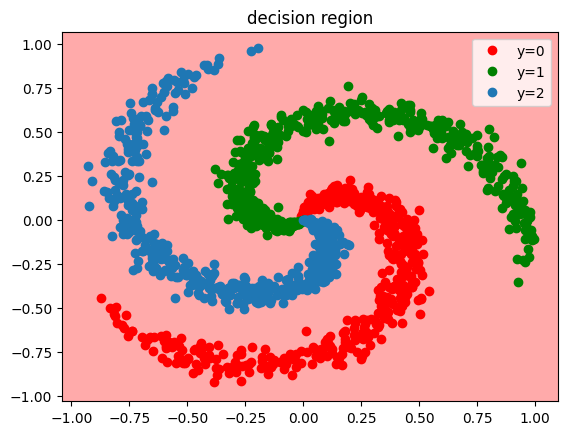

In [14]:
Layers = [2, 50, 3]
model = Net(Layers)
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.5)
train_loader = DataLoader(dataset=data_set, batch_size=20)
criterion = nn.CrossEntropyLoss()
Results['momentum 0.5'] = train(data_set, model, criterion, train_loader, optimizer, epochs=2)
plot_decision_regions_3class(model, data_set)

<!--Empty Space for separating topics-->


<h2>Compare the Results of Different Momentum Terms</h2>


The plot below compares results of different momentum terms. We see that in general. The Cost decreases proportionally to the momentum term, but larger momentum terms lead to larger oscillations. While the momentum term decreases faster, it seems that a momentum term of 0.2 reaches the smallest value for the cost. 


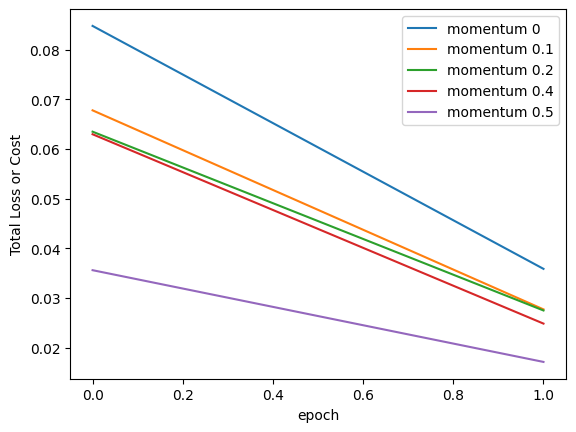

In [15]:
for key, value in Results.items():
    plt.plot(value['Loss'], label=key)
    plt.legend()
    plt.xlabel('epoch')
    plt.ylabel('Total Loss or Cost')

The  accuracy seems to be proportional to the momentum term.


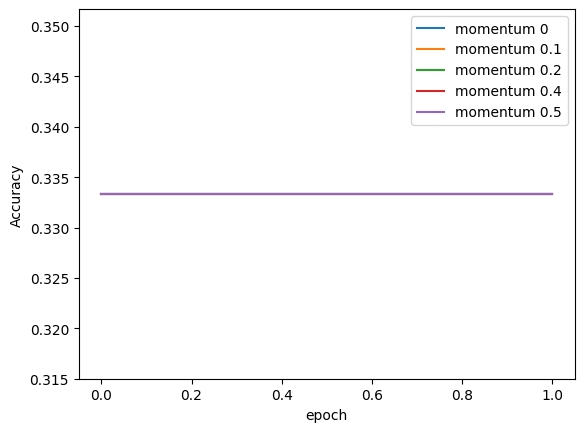

In [16]:
for key, value in Results.items():
    plt.plot(value['Accuracy'], label=key)
    plt.legend()
    plt.xlabel('epoch')
    plt.ylabel('Accuracy')

<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Srishti  |  Migrated Lab to Markdown and added to course repo in GitLab |



<hr>
-->

## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
